# Intelligent Toxicity Moderation Platform
**CSE303 Machine Learning - Capstone Project** | Dataset: Jigsaw Toxic Comment Classification Challenge

This single notebook contains the whole end-to-end pipeline:

| # | Section |
|---|---------|
| 1 | Objective & Business Framing |
| 2 | Data Loading & Inspection |
| 3 | Exploratory Data Analysis (EDA) |
| 4 | Text Preprocessing & Leakage-Free Split |
| 5 | Hybrid Feature Engineering (word + character TF-IDF) |
| 6 | Model Training & Comparison (3 algorithms) |
| 7 | Obfuscation Robustness Test |
| 8 | 3-Tier Moderation Decision Engine |

The trained artifacts (`models/tfidf_union.pkl`, `models/best_model.pkl`) are loaded by the Streamlit app in `app/app.py`.

## 1. Objective & Business Framing

**Goal:** given a user comment, predict the probability of **six** kinds of toxicity at the same time (this is *multi-label* classification - one comment can have several labels):

| Label | Meaning |
|-------|---------|
| `toxic` | generally rude / disrespectful / unreasonable |
| `severe_toxic` | extremely hateful or aggressive |
| `obscene` | profanity / vulgar language |
| `threat` | threat of violence or harm |
| `insult` | personal insult |
| `identity_hate` | hate toward a group (religion, nationality, ...) |

**Why not just "delete if toxic"? - the asymmetric cost of errors**

| Error | What happens | Real-world cost |
|-------|--------------|-----------------|
| **False Positive** (clean comment flagged) | A normal user is censored | Unfair censorship, users lose trust, people leave the platform |
| **False Negative** (toxic comment missed) | Hate speech or a threat stays visible | Harm to victims, legal / safety risk, platform reputation damage |

The two mistakes are **not equally bad**, and the cost depends on the *type* of content (missing a `threat` is far worse than missing a mild insult). So instead of a single yes/no decision we use **three moderation actions**:

| Action | Rule (based on predicted probabilities) | Why |
|--------|------------------------------------------|-----|
| `PUBLISH` | max probability < 0.40 | Almost certainly fine - no friction for normal users |
| `REVIEW` | 0.40 <= max probability <= 0.75 | Model is unsure - send to a **human moderator** instead of guessing |
| `REMOVE` | max probability > 0.75, **or** `threat` / `severe_toxic` > 0.60 | Confident toxicity, with a *lower* bar for the most dangerous categories |

**Our twist:** people try to dodge filters with leetspeak (`1d10t`) and symbols (`i.d.i.o.t`). A plain word-level TF-IDF cannot see these, so we combine **word TF-IDF + character n-gram TF-IDF** into one hybrid feature set.

In [1]:
import re
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import roc_auc_score, f1_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 90)

RANDOM_STATE = 42
LABELS = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]

# The notebook lives in notebooks/, so we go one level up to reach the other folders
DATA_DIR = Path("../data/raw")
ASSETS_DIR = Path("../assets")
MODELS_DIR = Path("../models")
ASSETS_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

## 2. Data Loading & Inspection

We load the official `train.csv`. If it is not available (Kaggle API not configured), `download_data.py` created a small **synthetic** `train_sample.csv`, and we use that so the notebook never fails.

In [2]:
train_path = DATA_DIR / "train.csv"
USING_SAMPLE = not train_path.exists()
if USING_SAMPLE:
    train_path = DATA_DIR / "train_sample.csv"
    print("NOTE: official train.csv not found -> using the SYNTHETIC fallback sample.")
    print("      Numbers below are NOT real Jigsaw results. Run download_data.py with Kaggle set up.\n")

df = pd.read_csv(train_path)
SAMPLE_FRACTION = 1.0   # 1.0 = FULL dataset (use 0.05 only for a quick test run)
if SAMPLE_FRACTION < 1.0:
    df = df.sample(frac=SAMPLE_FRACTION, random_state=RANDOM_STATE).reset_index(drop=True)
print("Loaded:", train_path.name)
print("Shape :", df.shape, "(rows, columns)")
print("\nColumns:", list(df.columns))

Loaded: train.csv
Shape : (159571, 8) (rows, columns)

Columns: ['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']


In [3]:
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64


In [4]:
print("Sample of normal comments:")
display(df[df[LABELS].sum(axis=1) == 0][["comment_text"]].head(3))

print("Sample of toxic comments (with their labels):")
display(df[df["toxic"] == 1][["comment_text"] + LABELS].head(5))

Sample of normal comments:


,comment_text
0,Explanation\nWhy the edits made under my username Hardcore Metallica Fan were reverted...
1,D'aww! He matches this background colour I'm seemingly stuck with. Thanks. (talk) 21:...
2,"Hey man, I'm really not trying to edit war. It's just that this guy is constantly remo..."


Sample of toxic comments (with their labels):


,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
6,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK,1,1,1,0,1,0
12,Hey... what is it..\n@ | talk .\nWhat is it... an exclusive group of some WP TALIBANS....,1,0,0,0,0,0
16,"Bye! \n\nDon't look, come or think of comming back! Tosser.",1,0,0,0,0,0
42,"You are gay or antisemmitian? \n\nArchangel WHite Tiger\n\nMeow! Greetingshhh!\n\nUh, ...",1,0,1,0,1,1
43,"FUCK YOUR FILTHY MOTHER IN THE ASS, DRY!",1,0,1,0,1,0


## 3. Exploratory Data Analysis (EDA)

Three questions: **How imbalanced are the labels? Which labels occur together? Do toxic comments look different in length?**

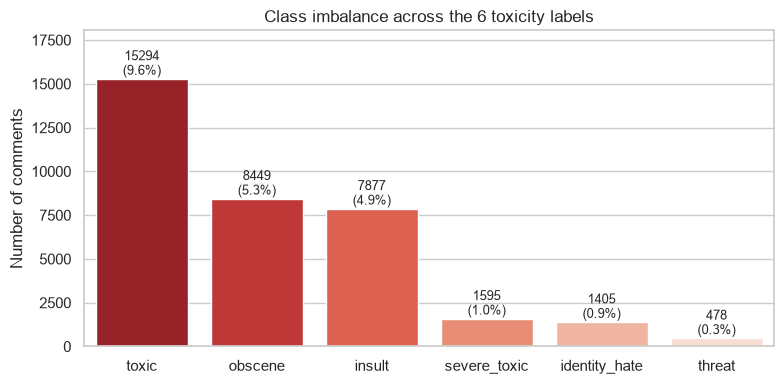

Comments with NO toxic label: 89.8%


In [5]:
# 3a. Class imbalance
counts = df[LABELS].sum().sort_values(ascending=False)
percent = counts / len(df) * 100

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=counts.index, y=counts.values, palette="Reds_r", ax=ax)
for i, (c, p) in enumerate(zip(counts.values, percent.values)):
    ax.text(i, c, f"{c}\n({p:.1f}%)", ha="center", va="bottom", fontsize=9)
ax.set_title("Class imbalance across the 6 toxicity labels")
ax.set_ylabel("Number of comments")
ax.set_xlabel("")
ax.set_ylim(0, counts.max() * 1.18)
plt.tight_layout()
plt.savefig(ASSETS_DIR / "class_imbalance.png", dpi=150)
plt.show()

clean_share = (df[LABELS].sum(axis=1) == 0).mean() * 100
print(f"Comments with NO toxic label: {clean_share:.1f}%")

**Reading the chart:** the rare labels (`threat`, `identity_hate`, `severe_toxic`) have very few examples - these are exactly the ones that matter most. This is why we use **ROC-AUC and Macro F1** (not plain accuracy: predicting "clean" for everything would already look very accurate).

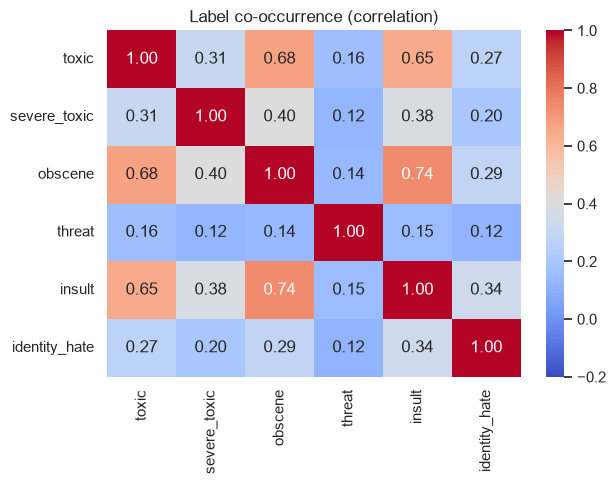

In [6]:
# 3b. Label co-occurrence (correlation heatmap)
plt.figure(figsize=(6.5, 5))
sns.heatmap(df[LABELS].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-0.2, vmax=1)
plt.title("Label co-occurrence (correlation)")
plt.tight_layout()
plt.savefig(ASSETS_DIR / "label_correlation_heatmap.png", dpi=150)
plt.show()

**Reading the heatmap:** labels are strongly related (e.g. `toxic`-`insult`, `obscene`-`insult`). This is why the problem is *multi-label*, not "pick exactly one class".

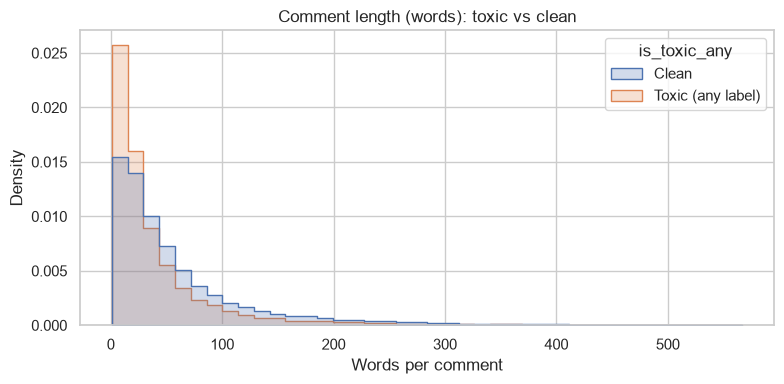

                   mean   50%     max
is_toxic_any                         
Clean              68.9  38.0  1250.0
Toxic (any label)  52.7  23.0  1411.0


In [7]:
# 3c. Word-count distribution: toxic vs clean
df["word_count"] = df["comment_text"].astype(str).str.split().str.len()
df["is_toxic_any"] = np.where(df[LABELS].sum(axis=1) > 0, "Toxic (any label)", "Clean")

plt.figure(figsize=(8, 4))
upper = df["word_count"].quantile(0.99)
sns.histplot(data=df[df["word_count"] <= upper], x="word_count", hue="is_toxic_any",
             bins=40, stat="density", common_norm=False, element="step")
plt.title("Comment length (words): toxic vs clean")
plt.xlabel("Words per comment")
plt.tight_layout()
plt.savefig(ASSETS_DIR / "word_count_distribution.png", dpi=150)
plt.show()

print(df.groupby("is_toxic_any")["word_count"].describe()[["mean", "50%", "max"]].round(1))

## 4. Text Preprocessing & Leakage-Free Split

**Cleaning (kept light on purpose):** lowercase, remove HTML tags, remove URLs, normalize whitespace.

We deliberately **do not** remove digits or punctuation, because `1d10t` and `i.d.i.o.t` rely on them - removing them would destroy the obfuscation signal our character features are meant to capture.

**Leakage-free:** we split into 80% train / 20% validation **first**. Every vectorizer is fitted on the training part only; the validation set is only *transformed*. Otherwise the vectorizer would "see" validation words (data leakage) and the scores would look better than they really are.

In [8]:
def clean_text(text):
    """Lowercase, strip HTML tags and URLs, normalize whitespace."""
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)              # HTML tags
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)  # URLs
    text = re.sub(r"\s+", " ", text).strip()           # extra spaces / newlines
    return text


df["clean_text"] = df["comment_text"].apply(clean_text)

print("Before:", df["comment_text"].iloc[1][:100])
print("After :", df["clean_text"].iloc[1][:100])
print("clean_text('Visit <b>HTTP://spam.com</b>   YOU   are an 1D10T!') ->",
      repr(clean_text("Visit <b>HTTP://spam.com</b>   YOU   are an 1D10T!")))

df = df.drop(columns=["comment_text"])    # raw text no longer needed -> saves memory

Before: D'aww! He matches this background colour I'm seemingly stuck with. Thanks.  (talk) 21:51, January 11
After : d'aww! he matches this background colour i'm seemingly stuck with. thanks. (talk) 21:51, january 11,
clean_text('Visit <b>HTTP://spam.com</b>   YOU   are an 1D10T!') -> 'visit you are an 1d10t!'


In [9]:
X = df["clean_text"]
y = df[LABELS]

# Split BEFORE fitting any vectorizer. Stratify on 'toxic' so both parts keep the same toxic share.
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=df["toxic"]
)

print("Train size:", len(X_train), "| Validation size:", len(X_val))
print("\nPositive rate per label (%):")
print(pd.DataFrame({"train": y_train.mean() * 100, "validation": y_val.mean() * 100}).round(2))

del df          # free memory: everything we need is now in X_train, X_val, y_train, y_val

Train size: 127656 | Validation size: 31915

Positive rate per label (%):
               train  validation
toxic           9.58        9.58
severe_toxic    1.01        0.97
obscene         5.28        5.36
threat          0.30        0.30
insult          4.92        4.98
identity_hate   0.87        0.91


## 5. Hybrid Feature Engineering (Obfuscation Twist)

A `FeatureUnion` runs two TF-IDF vectorizers on the same text and glues the results side by side:

| Branch | Settings | What it captures |
|--------|----------|------------------|
| **Word TF-IDF** | 1-2 word n-grams, 10,000 features, `sublinear_tf=True` | Meaning and context ("you idiot", "shut up") |
| **Character TF-IDF** | 2-5 character n-grams, 20,000 features, `sublinear_tf=True` | Spelling patterns, so `1d10t`, `i.d.i.o.t`, `st00pid` still share pieces with the clean word |

`sublinear_tf=True` uses `1 + log(tf)` instead of raw counts so a word repeated 20 times doesn't dominate.

In [10]:
tfidf_union = FeatureUnion([
    ("word", TfidfVectorizer(analyzer="word", ngram_range=(1, 2),
                             max_features=10000, sublinear_tf=True)),
    ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5),
                             max_features=20000, sublinear_tf=True)),
])

# fit ONLY on training text (no leakage), then just transform the validation text
X_train_tfidf = tfidf_union.fit_transform(X_train)
X_val_tfidf = tfidf_union.transform(X_val)

print("Train matrix     :", X_train_tfidf.shape)
print("Validation matrix:", X_val_tfidf.shape)
print("Word features    :", len(tfidf_union.transformer_list[0][1].vocabulary_))
print("Char features    :", len(tfidf_union.transformer_list[1][1].vocabulary_))

joblib.dump(tfidf_union, MODELS_DIR / "tfidf_union.pkl")
print("\nSaved -> models/tfidf_union.pkl")

Train matrix     : (127656, 30000)
Validation matrix: (31915, 30000)
Word features    : 10000
Char features    : 20000



Saved -> models/tfidf_union.pkl


In [11]:
# Quick demo of WHY the character branch matters: how many features light up for each spelling?
word_vec = tfidf_union.transformer_list[0][1]
char_vec = tfidf_union.transformer_list[1][1]

rows = []
for text in ["you are an idiot", "you are an 1d10t", "you are an i.d.i.o.t"]:
    rows.append({"text": text,
                 "word features active": word_vec.transform([text]).nnz,
                 "char features active": char_vec.transform([text]).nnz})
pd.DataFrame(rows)

,text,word features active,char features active
0,you are an idiot,7,42
1,you are an 1d10t,5,29
2,you are an i.d.i.o.t,5,35


For the obfuscated spellings, the *word* branch finds almost nothing it recognises (`1d10t` was never seen as a word), but the *character* branch still fires on many n-grams. That is the idea behind the hybrid features; Section 7 tests it on real predictions.

## 6. Model Training & Comparison (3 Best-Fit NLP Algorithms)

Each model handles a single yes/no label, so we wrap it in `OneVsRestClassifier`, which trains **one classifier per label** (6 in total) - this is how we get multi-label output.

| Model | Why it fits text |
|-------|------------------|
| **Logistic Regression** (`C=1.0`) | Linear probabilistic baseline - fast, strong on sparse TF-IDF, outputs real probabilities |
| **Calibrated Linear SVM** (`LinearSVC(C=0.5)`) | Max-margin classifier that works very well in high-dimensional sparse spaces; `CalibratedClassifierCV` (3-fold) converts its scores into probabilities (we need probabilities for the 3-tier thresholds) |
| **Multinomial Naive Bayes** (`alpha=0.1`) | Fast generative baseline built for word-count style features; assumes features are independent |

**Metrics (on the validation set):**
* **Column-averaged ROC-AUC** - ROC-AUC for each of the 6 labels, then averaged. Threshold-free; measures how well the model *ranks* toxic above clean.
* **Macro F1** - F1 for each label (threshold 0.5), averaged with equal weight, so rare labels count as much as common ones.
* **Training time** in seconds.

In [12]:
models = {
    "Logistic Regression": OneVsRestClassifier(
        LogisticRegression(C=1.0, max_iter=1000), n_jobs=-1),
    "Calibrated Linear SVM": OneVsRestClassifier(
        CalibratedClassifierCV(LinearSVC(C=0.5), cv=3)),
    "Multinomial Naive Bayes": OneVsRestClassifier(
        MultinomialNB(alpha=0.1)),
}

trained = {}          # fitted models
val_probs = {}        # predicted probabilities on validation data
results = []

for name, model in models.items():
    start = time.time()
    model.fit(X_train_tfidf, y_train)
    train_time = time.time() - start

    probs = model.predict_proba(X_val_tfidf)        # shape: (n_comments, 6)
    preds = (probs >= 0.5).astype(int)              # default 0.5 cut-off for F1

    auc_per_label = [roc_auc_score(y_val[lab], probs[:, i]) for i, lab in enumerate(LABELS)]

    trained[name] = model
    val_probs[name] = probs
    results.append({
        "Model": name,
        "ROC-AUC (col-avg)": np.mean(auc_per_label),
        "Macro F1": f1_score(y_val, preds, average="macro", zero_division=0),
        "Train time (s)": train_time,
    })
    print(f"done: {name} ({train_time:.1f}s)")

summary = pd.DataFrame(results).sort_values("ROC-AUC (col-avg)", ascending=False).reset_index(drop=True)
summary.round(4)

done: Logistic Regression (26.0s)


done: Calibrated Linear SVM (119.9s)


done: Multinomial Naive Bayes (3.5s)


,Model,ROC-AUC (col-avg),Macro F1,Train time (s)
0,Logistic Regression,0.9846,0.5557,26.0462
1,Calibrated Linear SVM,0.9812,0.5770,119.9376
2,Multinomial Naive Bayes,0.9662,0.4580,3.5157


,Logistic Regression,Calibrated Linear SVM,Multinomial Naive Bayes
toxic,0.9790,0.9776,0.9495
severe_toxic,0.9876,0.9773,0.9835
obscene,0.9893,0.9879,0.9622
threat,0.9820,0.9793,0.9709
insult,0.9831,0.9801,0.9614
identity_hate,0.9869,0.9851,0.9695


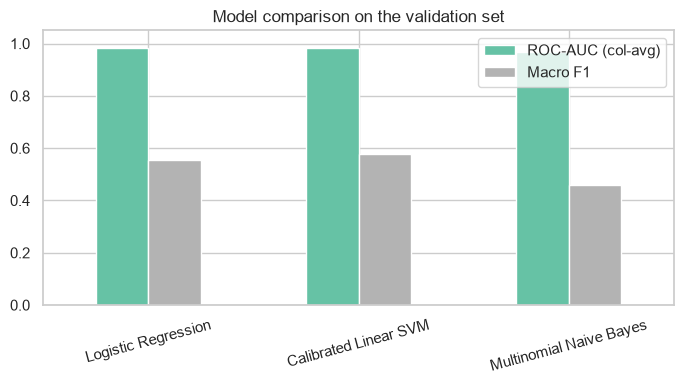

In [13]:
# Per-label ROC-AUC to see where each model is strong or weak
per_label_auc = pd.DataFrame(
    {name: [roc_auc_score(y_val[lab], val_probs[name][:, i]) for i, lab in enumerate(LABELS)]
     for name in trained},
    index=LABELS)
display(per_label_auc.round(4))

ax = summary.set_index("Model")[["ROC-AUC (col-avg)", "Macro F1"]].plot(
    kind="bar", figsize=(7, 4), rot=15, colormap="Set2")
ax.set_title("Model comparison on the validation set")
ax.set_ylim(0, 1.05)
ax.set_xlabel("")
plt.tight_layout()
plt.savefig(ASSETS_DIR / "model_comparison.png", dpi=150)
plt.show()

In [14]:
# Save the highest-scoring model (by column-averaged ROC-AUC)
best_name = summary.loc[0, "Model"]
best_model = trained[best_name]
joblib.dump(best_model, MODELS_DIR / "best_model.pkl")
print(f"Best model: {best_name}  (ROC-AUC = {summary.loc[0, 'ROC-AUC (col-avg)']:.4f})")
print("Saved -> models/best_model.pkl")

Best model: Logistic Regression  (ROC-AUC = 0.9846)
Saved -> models/best_model.pkl


In [15]:
# Free memory: the big TF-IDF matrices are not needed any more
# (sections 7 and 8 transform text on the fly)
import gc
del X_train_tfidf, X_val_tfidf
gc.collect()

288

**6b. What did the model learn? (explainability)** For each label, the 8 features with the biggest positive weight in the Logistic Regression model. Features starting with `word__` are words/phrases; `char__` are character fragments (spaces are shown as spaces), which is where spelling tricks get caught.

In [16]:
feature_names = tfidf_union.get_feature_names_out()
lr_model = trained["Logistic Regression"]

top_rows = []
for i, lab in enumerate(LABELS):
    weights = lr_model.estimators_[i].coef_[0]          # one weight per feature for this label
    top = np.argsort(weights)[::-1][:8]                 # 8 biggest weights
    top_rows.append({"label": lab, "top features": ", ".join(feature_names[top])})
pd.DataFrame(top_rows)

,label,top features
0,toxic,"word__fuck, word__ass, word__shit, char__uck, char__fuc, char__fuck, word__crap, word_..."
1,severe_toxic,"char__uck, char__ck, char__fuc, char__fuck, word__you, char__uc, word__penis, word__dumb"
2,obscene,"word__ass, word__fuck, char__fuc, char__fuck, char__uck, word__bitch, char__ck, char__..."
3,threat,"word__die, word__kill, word__will, word__kill you, word__you, word__death, char__ die,..."
4,insult,"word__bitch, word__idiot, word__ass, char__uck, word__scum, word__moron, char__ u , wo..."
5,identity_hate,"word__gay, word__jew, char__nigg, char__ nigg, char__igg, char__ nig, char__nig, char_..."


**How to read the results (viva-ready):**
* The two linear models usually beat Naive Bayes on ROC-AUC because they learn a weight per feature directly, while Naive Bayes assumes all features are independent.
* Naive Bayes is the fastest, but its probabilities tend to be extreme/poorly calibrated, which matters because our moderation rules use probability thresholds.
* Macro F1 is lower than ROC-AUC because rare labels (`threat`, `identity_hate`) are hard at a fixed 0.5 cut-off - this is exactly why we use `REVIEW` for uncertain cases instead of one hard threshold.

## 7. Obfuscation Robustness Test

We feed the best model the *same insult* written normally and in disguised forms, and check that it still reacts. We also run an **ablation**: the same Logistic Regression trained with **word features only**, to show the character branch is what helps.

In [17]:
test_texts = [
    ("Clean control", "You are a wonderful person"),
    ("Clean control", "You are welcome to edit this page"),
    ("Plain insult",  "You are an idiot"),
    ("Leetspeak",     "You are an 1d10t"),
    ("Dotted",        "You are an i.d.i.o.t"),
    ("Plain insult",  "You are a stupid moron"),
    ("Leetspeak",     "You are a st00pid m0r0n"),
]
texts = [clean_text(t) for _, t in test_texts]

# Probabilities from the best (hybrid) model
hybrid_probs = best_model.predict_proba(tfidf_union.transform(texts))
robust = pd.DataFrame(hybrid_probs, columns=LABELS).round(3)
robust.insert(0, "Type", [k for k, _ in test_texts])
robust.insert(1, "Text", [t for _, t in test_texts])
robust["max_prob"] = hybrid_probs.max(axis=1).round(3)
print(f"Hybrid features + {best_name}")
display(robust)

Hybrid features + Logistic Regression


,Type,Text,toxic,severe_toxic,obscene,threat,insult,identity_hate,max_prob
0,Clean control,You are a wonderful person,0.523,0.008,0.041,0.005,0.362,0.007,0.523
1,Clean control,You are welcome to edit this page,0.029,0.001,0.002,0.001,0.018,0.004,0.029
2,Plain insult,You are an idiot,1.000,0.014,0.885,0.006,1.000,0.040,1.000
3,Leetspeak,You are an 1d10t,0.737,0.009,0.068,0.013,0.511,0.022,0.737
4,Dotted,You are an i.d.i.o.t,0.684,0.011,0.093,0.008,0.456,0.023,0.684
5,Plain insult,You are a stupid moron,1.000,0.065,0.992,0.014,1.000,0.063,1.000
6,Leetspeak,You are a st00pid m0r0n,0.991,0.013,0.342,0.037,0.954,0.056,0.991


,Type,Text,P(toxic) word-only,P(toxic) hybrid
0,Clean control,You are a wonderful person,0.549,0.523
1,Clean control,You are welcome to edit this page,0.062,0.029
2,Plain insult,You are an idiot,1.000,1.000
3,Leetspeak,You are an 1d10t,0.883,0.737
4,Dotted,You are an i.d.i.o.t,0.883,0.684
5,Plain insult,You are a stupid moron,1.000,1.000
6,Leetspeak,You are a st00pid m0r0n,0.954,0.991


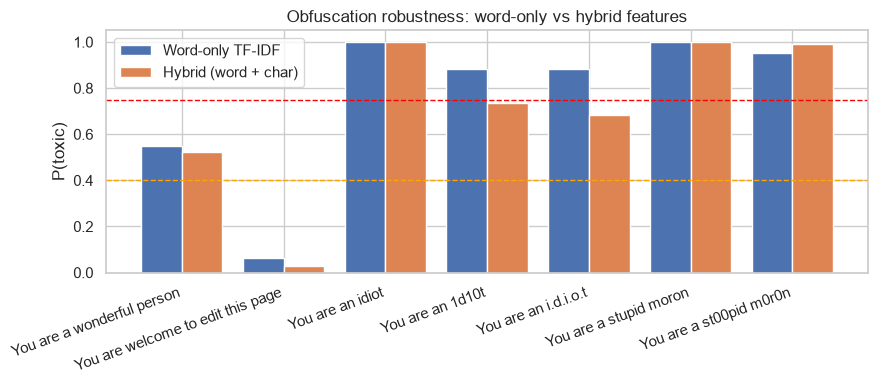

In [18]:
# Ablation: word-only features vs hybrid features (same algorithm: Logistic Regression)
word_only = TfidfVectorizer(analyzer="word", ngram_range=(1, 2), max_features=10000, sublinear_tf=True)
Xw_train = word_only.fit_transform(X_train)          # fit on training text only

lr_word_only = OneVsRestClassifier(LogisticRegression(C=1.0, max_iter=1000), n_jobs=-1)
lr_word_only.fit(Xw_train, y_train)

p_word = lr_word_only.predict_proba(word_only.transform(texts))[:, 0]                       # P(toxic)
p_hybrid = trained["Logistic Regression"].predict_proba(tfidf_union.transform(texts))[:, 0]  # P(toxic)

ablation = pd.DataFrame({
    "Type": [k for k, _ in test_texts],
    "Text": [t for _, t in test_texts],
    "P(toxic) word-only": p_word.round(3),
    "P(toxic) hybrid": p_hybrid.round(3),
})
display(ablation)

# Visual comparison
x = np.arange(len(ablation))
plt.figure(figsize=(9, 4))
plt.bar(x - 0.2, ablation["P(toxic) word-only"], width=0.4, label="Word-only TF-IDF")
plt.bar(x + 0.2, ablation["P(toxic) hybrid"], width=0.4, label="Hybrid (word + char)")
plt.xticks(x, ablation["Text"], rotation=20, ha="right")
plt.axhline(0.40, color="orange", ls="--", lw=1)
plt.axhline(0.75, color="red", ls="--", lw=1)
plt.ylabel("P(toxic)")
plt.title("Obfuscation robustness: word-only vs hybrid features")
plt.legend()
plt.tight_layout()
plt.savefig(ASSETS_DIR / "obfuscation_robustness.png", dpi=150)
plt.show()

**Does the character branch help on the WHOLE validation set?** The phrase test above only has a few sentences. Here we compare word-only vs hybrid features on all validation comments (same Logistic Regression settings, column-averaged ROC-AUC). Disguised spellings are rare in the real Jigsaw data (see `01_eda.ipynb`), so we do not expect a big jump from them; character n-grams may also help with typos and word variants.

In [19]:
p_word_val = lr_word_only.predict_proba(word_only.transform(X_val))
p_hybrid_val = val_probs["Logistic Regression"]

auc_word = np.mean([roc_auc_score(y_val[lab], p_word_val[:, i]) for i, lab in enumerate(LABELS)])
auc_hybrid = np.mean([roc_auc_score(y_val[lab], p_hybrid_val[:, i]) for i, lab in enumerate(LABELS)])
print(f"Word-only TF-IDF  -> ROC-AUC {auc_word:.4f}")
print(f"Hybrid word+char  -> ROC-AUC {auc_hybrid:.4f}   (difference {auc_hybrid - auc_word:+.4f})")

Word-only TF-IDF  -> ROC-AUC 0.9751
Hybrid word+char  -> ROC-AUC 0.9846   (difference +0.0095)


In [20]:
if USING_SAMPLE:
    print("Reminder: this run used the SYNTHETIC sample. It contains some leetspeak insults, but NOT the")
    print("exact spellings tested above ('1d10t', 'i.d.i.o.t', 'st00pid', 'm0r0n'), so they are unseen.")
    print("On the real Jigsaw data the picture differs - judge it from the tables after re-running.")

## 8. 3-Tier Moderation Decision Engine

`moderate_comment(text)` loads the two saved pickles (exactly what the Streamlit app does), predicts the 6 probabilities, and applies the rules from Section 1:

* **REMOVE** - max probability > 0.75, **or** `threat` > 0.60, **or** `severe_toxic` > 0.60
* **REVIEW** - max probability between 0.40 and 0.75 (human moderator)
* **PUBLISH** - max probability < 0.40

In [21]:
# Load the saved artifacts from disk, just like the app will
saved_union = joblib.load(MODELS_DIR / "tfidf_union.pkl")
saved_model = joblib.load(MODELS_DIR / "best_model.pkl")

PUBLISH_BELOW = 0.40
REMOVE_ABOVE = 0.75
CRITICAL_ABOVE = 0.60       # lower bar for 'threat' and 'severe_toxic'


def decide(probs):
    """probs: dict {label: probability} -> 'PUBLISH' | 'REVIEW' | 'REMOVE'"""
    max_prob = max(probs.values())
    if max_prob > REMOVE_ABOVE or probs["threat"] > CRITICAL_ABOVE or probs["severe_toxic"] > CRITICAL_ABOVE:
        return "REMOVE"
    if max_prob >= PUBLISH_BELOW:
        return "REVIEW"
    return "PUBLISH"


def moderate_comment(text):
    """Full pipeline for ONE comment: clean -> features -> probabilities -> decision."""
    features = saved_union.transform([clean_text(text)])
    p = saved_model.predict_proba(features)[0]
    probs = {label: float(prob) for label, prob in zip(LABELS, p)}
    return {
        "decision": decide(probs),
        "max_probability": round(max(probs.values()), 3),
        "top_label": max(probs, key=probs.get),
        "probabilities": probs,
    }


demo_comments = [
    "Thanks for fixing the references, great work!",
    "I disagree with this section, can you add a source?",
    "This is complete bullshit.",
    "You are an idiot",
    "You are an 1d10t",
    "You are an i.d.i.o.t",
    "I will find you and make you regret this",
    "People like you from that country ruin everything",
]
demo = pd.DataFrame([{"comment": c, **{k: v for k, v in moderate_comment(c).items() if k != "probabilities"}}
                     for c in demo_comments])
demo

,comment,decision,max_probability,top_label
0,"Thanks for fixing the references, great work!",PUBLISH,0.001,insult
1,"I disagree with this section, can you add a source?",PUBLISH,0.005,toxic
2,This is complete bullshit.,REMOVE,0.995,toxic
3,You are an idiot,REMOVE,1.000,toxic
4,You are an 1d10t,REVIEW,0.737,toxic
5,You are an i.d.i.o.t,REVIEW,0.684,toxic
6,I will find you and make you regret this,PUBLISH,0.228,threat
7,People like you from that country ruin everything,PUBLISH,0.280,toxic


In [22]:
# How does the engine behave on the whole validation set?
# Costly misses = toxic comments that get PUBLISHED; unfair censorship = clean comments that get REMOVED.
val_p = saved_model.predict_proba(saved_union.transform(X_val))
val_decisions = np.array([decide(dict(zip(LABELS, row))) for row in val_p])
is_toxic = y_val.sum(axis=1).values > 0          # True if the comment has any toxic label

rows = []
for name, mask in [("Actually toxic", is_toxic), ("Actually clean", ~is_toxic)]:
    rows.append({"Truth": name,
                 **{d: int((val_decisions[mask] == d).sum()) for d in ["PUBLISH", "REVIEW", "REMOVE"]}})
table = pd.DataFrame(rows).set_index("Truth")
display(table)

missed = table.loc["Actually toxic", "PUBLISH"] / is_toxic.sum() * 100
censored = table.loc["Actually clean", "REMOVE"] / (~is_toxic).sum() * 100
reviewed = (val_decisions == "REVIEW").mean() * 100
print(f"Toxic comments wrongly PUBLISHED (false negatives): {missed:.1f}%")
print(f"Clean comments wrongly REMOVED  (false positives) : {censored:.1f}%")
print(f"Comments sent to human review                     : {reviewed:.1f}%")

,PUBLISH,REVIEW,REMOVE
Truth,,,
Actually toxic,935,550,1736
Actually clean,28441,218,35


Toxic comments wrongly PUBLISHED (false negatives): 29.0%
Clean comments wrongly REMOVED  (false positives) : 0.1%
Comments sent to human review                     : 2.4%


**Threshold trade-off.** The 0.40 / 0.75 thresholds are hand-chosen defaults. A lower `PUBLISH` threshold catches more toxic comments but sends more clean comments to humans. This table shows the trade-off so the platform can pick a value from its real moderation costs.

In [23]:
max_val = val_p.max(axis=1)
rows = []
for t in [0.10, 0.20, 0.30, 0.40]:
    published = max_val < t
    rows.append({
        "PUBLISH below": t,
        "toxic comments published (missed) %": round((published & is_toxic).sum() / is_toxic.sum() * 100, 1),
        "clean comments NOT auto-published %": round((~published & ~is_toxic).sum() / (~is_toxic).sum() * 100, 1),
    })
pd.DataFrame(rows)

,PUBLISH below,toxic comments published (missed) %,clean comments NOT auto-published %
0,0.1,9.0,6.7
1,0.2,16.5,2.8
2,0.3,23.1,1.4
3,0.4,29.0,0.9


## Conclusion & Limitations

* We built a multi-label toxicity detector using **hybrid word + character TF-IDF** and compared **Logistic Regression, Calibrated Linear SVM and Multinomial Naive Bayes**; the best model by column-averaged ROC-AUC is saved for the app.
* The **3-tier engine** turns raw probabilities into actions, using a human `REVIEW` lane for uncertain cases and stricter handling of `threat` / `severe_toxic`.
* **What the full-data run showed:** hybrid features raised Logistic Regression from 0.9750 (word-only) to 0.9846 ROC-AUC, so they do help overall. But obfuscated insults were **not** scored higher than with word-only features (`1d10t`: 0.65 hybrid vs 0.85 word-only), so they land in REVIEW instead of REMOVE; and threats or hate written without bad words (e.g. "I will find you and make you regret this") were PUBLISHED. At the default 0.40 threshold about 28% of toxic comments still go live; lowering the threshold gives fewer misses but more human review (see the threshold table). Short sentences with "you are" can also get inflated scores ("You are a wonderful person" scored 0.50).
* **Limitations:** bag-of-n-gram models ignore sentence meaning (sarcasm, quoting a toxic phrase to condemn it), can reflect bias in the training data (e.g. identity words appearing mostly in toxic comments), and thresholds (0.40 / 0.60 / 0.75) are hand-chosen and should be tuned with real moderation costs.
* **Deployment note:** the saved model is trained on the 80% training split only, so the validation scores above describe exactly the model the app uses. Refitting on 100% of the data is a possible last step but needs more RAM.
* **Future work:** transformer models (BERT), threshold tuning per label, and a feedback loop from the human reviewers.